In [3]:
# imports

from pathlib import Path
import requests

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [19]:
def download_Auto_dataset():

    dataset_url = "https://www.statlearning.com/s/Auto.csv"
    response = requests.get(dataset_url)

    response.raise_for_status()

    download_directory = Path.cwd().parent / "datasets"
    file_name = Path(dataset_url).name
    dataset_path = download_directory / file_name

    with open(dataset_path, "wb") as file:
        file.write(response.content)

def get_Auto_dataset():

    dataset_directory = Path.cwd().parent / "datasets"
    Auto_path = dataset_directory / "Auto.csv"

    try:
        df = pd.read_csv(Auto_path)
        return df
    except IOError:
        print("Error reading file") 

In [21]:
auto = get_Auto_dataset()
auto.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [37]:
# removing missing files from horsepower

auto_cleaned = auto.replace(['?'], np.nan).dropna()

In [40]:
auto_cleaned['horsepower'] = auto_cleaned['horsepower'].astype(int)

In [46]:
numeric_auto_cleaned = auto_cleaned.select_dtypes(include = 'number')
categorical_auto_cleaned = auto_cleaned.select_dtypes(include = 'str')

In [49]:
numeric_auto_cleaned.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin
count,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000
mean,23.445918,5.471939,194.411990,104.469388,2977.584184,15.541327,75.979592,1.576531
std,7.805007,1.705783,104.644004,38.491160,849.402560,2.758864,3.683737,0.805518
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.000000,4.000000,105.000000,75.000000,2225.250000,13.775000,73.000000,1.000000
50%,22.750000,4.000000,151.000000,93.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,275.750000,126.000000,3614.750000,17.025000,79.000000,2.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000,3.000000


In [51]:
range_numeric = numeric_auto_cleaned.agg(['min', 'max'])

In [53]:
range_numeric

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin
min,9.0,3,68.0,46,1613,8.0,70,1
max,46.6,8,455.0,230,5140,24.8,82,3


In [54]:
mean_std_numeric = numeric_auto_cleaned.agg(['mean', 'std'])

In [ ]:
mean_std_numeric

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin
mean,23.445918,5.471939,194.411990,104.469388,2977.584184,15.541327,75.979592,1.576531
std,7.805007,1.705783,104.644004,38.491160,849.402560,2.758864,3.683737,0.805518


In [56]:
numeric_auto_cleaned_subset = numeric_auto_cleaned.drop(numeric_auto_cleaned.index[10:86])

In [57]:
numeric_auto_cleaned_subset.agg(['min', 'mean', 'std', 'max'])

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin
min,11.000000,3.000000,68.000000,46.000000,1649.00000,8.500000,70.000000,1.000000
mean,24.407595,5.373418,187.512658,100.848101,2936.53481,15.717405,77.136076,1.601266
std,7.863285,1.654179,100.114616,35.954147,811.87445,2.713876,3.123464,0.819910
max,46.600000,8.000000,455.000000,230.000000,4997.00000,24.800000,82.000000,3.000000


array([[<Axes: xlabel='mpg', ylabel='mpg'>,
        <Axes: xlabel='cylinders', ylabel='mpg'>,
        <Axes: xlabel='displacement', ylabel='mpg'>,
        <Axes: xlabel='horsepower', ylabel='mpg'>,
        <Axes: xlabel='weight', ylabel='mpg'>,
        <Axes: xlabel='acceleration', ylabel='mpg'>,
        <Axes: xlabel='year', ylabel='mpg'>,
        <Axes: xlabel='origin', ylabel='mpg'>],
       [<Axes: xlabel='mpg', ylabel='cylinders'>,
        <Axes: xlabel='cylinders', ylabel='cylinders'>,
        <Axes: xlabel='displacement', ylabel='cylinders'>,
        <Axes: xlabel='horsepower', ylabel='cylinders'>,
        <Axes: xlabel='weight', ylabel='cylinders'>,
        <Axes: xlabel='acceleration', ylabel='cylinders'>,
        <Axes: xlabel='year', ylabel='cylinders'>,
        <Axes: xlabel='origin', ylabel='cylinders'>],
       [<Axes: xlabel='mpg', ylabel='displacement'>,
        <Axes: xlabel='cylinders', ylabel='displacement'>,
        <Axes: xlabel='displacement', ylabel='displacement

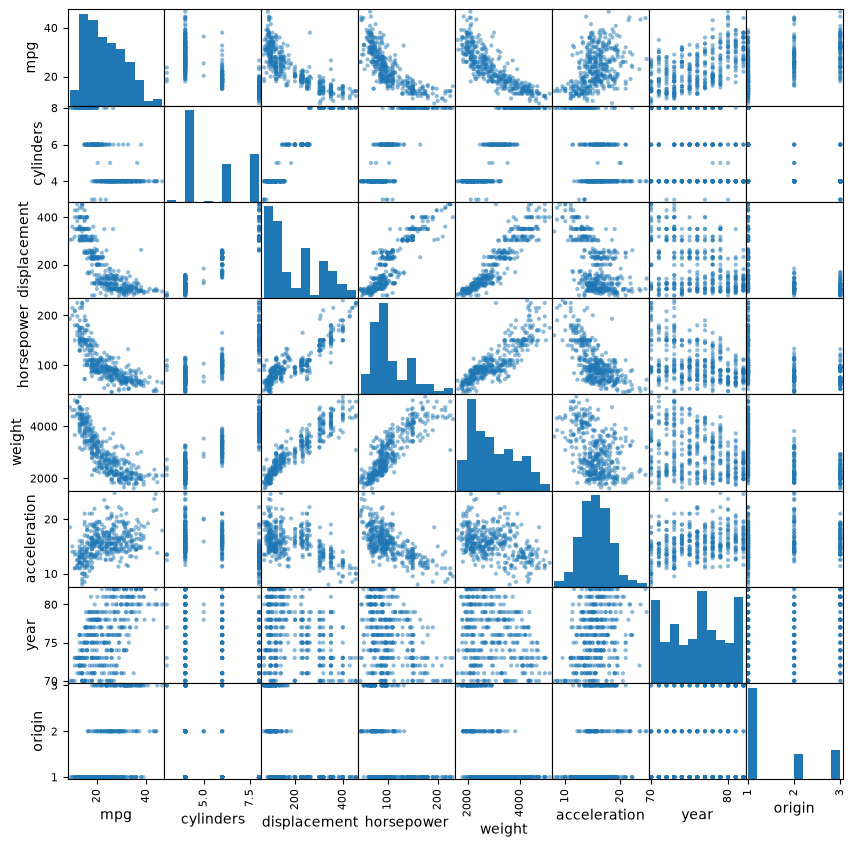

In [63]:
pd.plotting.scatter_matrix(numeric_auto_cleaned, figsize = (10,10))

From the scatter matrix, we see that cylinders, acceleration, and origin are features that would be better coded as categorical instead of numerical.

Moreover, it appears there is a non-linear relationship between various features. Not that there aren't correlated features. Things like displacmenet and weight, displacement and horsepower are linearly correlated. 

If we were to predict mgh, I would first bin year. 

Convert various cylinders, origin into categorial data. I would then need to graph some more results to figure out the relationship.

Lastly, I would find polynomial regression to be more useful. 